In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path("..").resolve()))

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold

from src.datasets import load_benchmark_dataset
from src.samplers import smote, random_oversample_minority
from src.models import build_c45_proxy
from src.metrics import compute_rates

X, y = load_benchmark_dataset("mammography")
print(f"Mammography shape: {X.shape}, Majority: {np.sum(y==0)}, Minority: {np.sum(y==1)}")


Mammography shape: (11183, 6), Majority: 10923, Minority: 260


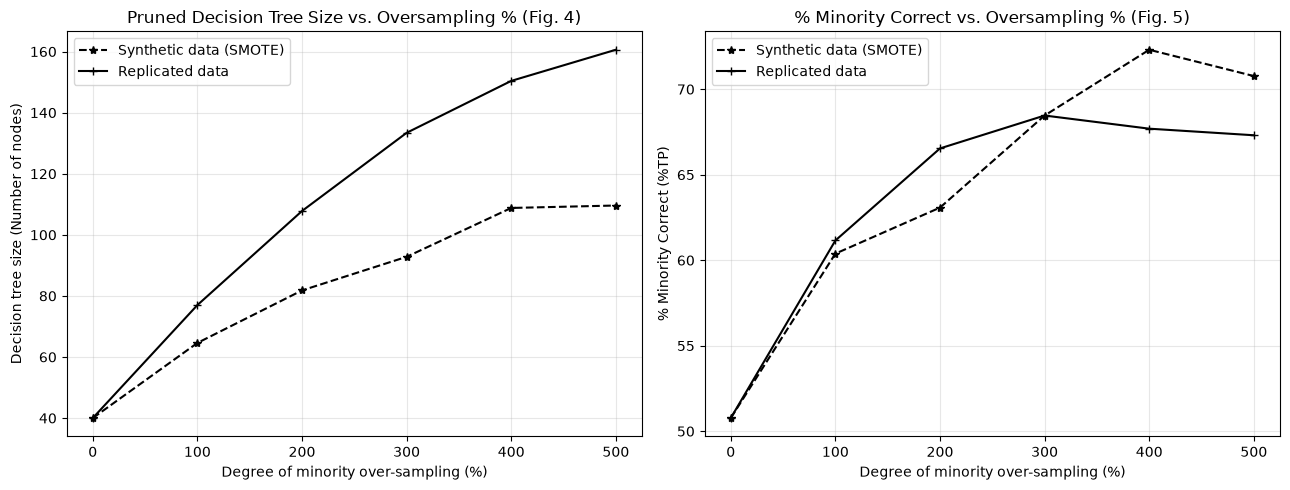

In [2]:
levels = [0, 100, 200, 300, 400, 500]
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

smote_nodes, rep_nodes = [], []
smote_tp, rep_tp = [], []

for pct in levels:
    s_n, r_n, s_t, r_t = [], [], [], []
    for fold, (tr, te) in enumerate(skf.split(X, y)):
        X_tr, y_tr = X[tr], y[tr]
        X_te, y_te = X[te], y[te]
        X_min, X_maj = X_tr[y_tr == 1], X_tr[y_tr == 0]

        # 1. SMOTE oversampling
        if pct > 0:
            syn = smote(X_min, N=pct, k=5, random_state=42 + fold)
            X_s = np.vstack([X_maj, X_min, syn])
            y_s = np.array([0]*len(X_maj) + [1]*(len(X_min) + len(syn)))
        else:
            X_s, y_s = X_tr, y_tr

        clf_s = build_c45_proxy(ccp_alpha=0.001, random_state=42 + fold)
        clf_s.fit(X_s, y_s)
        _, tp_s = compute_rates(y_te, clf_s.predict(X_te))
        s_n.append(clf_s.tree_.node_count)
        s_t.append(tp_s)

        # 2. Random replication
        if pct > 0:
            rep = random_oversample_minority(X_min, N=pct, random_state=42 + fold)
            X_r = np.vstack([X_maj, X_min, rep])
            y_r = np.array([0]*len(X_maj) + [1]*(len(X_min) + len(rep)))
        else:
            X_r, y_r = X_tr, y_tr

        clf_r = build_c45_proxy(ccp_alpha=0.001, random_state=42 + fold)
        clf_r.fit(X_r, y_r)
        _, tp_r = compute_rates(y_te, clf_r.predict(X_te))
        r_n.append(clf_r.tree_.node_count)
        r_t.append(tp_r)

    smote_nodes.append(np.mean(s_n))
    rep_nodes.append(np.mean(r_n))
    smote_tp.append(np.mean(s_t))
    rep_tp.append(np.mean(r_t))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(levels, smote_nodes, "k*--", label="Synthetic data (SMOTE)")
axes[0].plot(levels, rep_nodes, "k+-", label="Replicated data")
axes[0].set_title("Pruned Decision Tree Size vs. Oversampling % (Fig. 4)")
axes[0].set_xlabel("Degree of minority over-sampling (%)")
axes[0].set_ylabel("Decision tree size (Number of nodes)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(levels, smote_tp, "k*--", label="Synthetic data (SMOTE)")
axes[1].plot(levels, rep_tp, "k+-", label="Replicated data")
axes[1].set_title("% Minority Correct vs. Oversampling % (Fig. 5)")
axes[1].set_xlabel("Degree of minority over-sampling (%)")
axes[1].set_ylabel("% Minority Correct (%TP)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()